# COM7022 Machine Learning – Task 1: Clustering products by characteristics and sales performance

**Student ID:** _add your ID here_

**Goal.** Group the products in `Sales-[5444].csv` into segments that the business can act on (pricing, stock, promotion), using several clustering methods and comparing them.

**How to use this notebook.** It is a worked reference. Every step runs, but the cells marked **✍️ Your analysis** are where *you* write the interpretation and justification in your own words. Those paragraphs are what earn the analysis marks, so don't skip them. Run the cells top to bottom (Kernel → Restart & Run All) and screenshot the outputs for your report.

Notebook outline
1. Setup and load
2. Data understanding and quality audit
3. Cleaning and feature engineering
4. Exploratory analysis
5. Feature selection and transformation (scaling, normalisation, categorical encoding)
6. Dimensionality reduction (PCA)
7. K-Means
8. Hierarchical (agglomerative) clustering
9. DBSCAN
10. Model comparison and stability
11. Sensitivity check: adding categorical features
12. Cluster profiles and business interpretation
13. Export

## 1. Setup and load

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42  # fixed seed so results are reproducible

# One colour per cluster, always in the same order; grey is reserved for DBSCAN noise
CLUSTER_COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
NOISE_COLOUR = '#9a9a96'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

In [2]:
# The CSV must be in the same folder as this notebook. Both spellings of the file name are accepted.
import os
for name in ['Sales-5444.csv', 'Sales-[5444].csv', 'Sales_5444.csv']:
    if os.path.exists(name):
        DATA_FILE = name
        break
else:
    raise FileNotFoundError('Put Sales-5444.csv in this folder: ' + os.getcwd())
raw = pd.read_csv(DATA_FILE)
print('Shape:', raw.shape)
raw.head()

Shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


## 2. Data understanding and quality audit

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


In [4]:
# Missing values per column, as a count and a percentage
missing = pd.DataFrame({'missing': raw.isna().sum(),
                        'pct': (raw.isna().mean() * 100).round(1)})
missing

,missing,pct
Item_Name,1,0.1
details,0,0.0
Catatory,3,0.3
price,5,0.5
priceWithCurrency,1,0.1
available,111,11.1
text,3,0.3
sold,8,0.8
lastUpdated,53,5.3
itemLocation,0,0.0


In [5]:
raw.describe()

,price,available,sold
count,995.000000,889.000000,992.000000
mean,46.433467,20.046119,775.246976
std,35.551712,61.547985,3211.433298
min,3.000000,2.000000,1.000000
25%,22.990000,5.000000,14.000000
50%,35.710000,10.000000,49.500000
75%,59.000000,10.000000,324.750000
max,259.090000,842.000000,54052.000000


In [6]:
# Duplicate checks: exact duplicates, and same listing title at the same price
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate (details, price) pairs:', raw.duplicated(subset=['details', 'price']).sum())

Exact duplicate rows: 0
Duplicate (details, price) pairs: 7


In [7]:
# The 'Catatory' column (sic) is free text: many spellings of the same thing
print('Distinct category labels:', raw['Catatory'].nunique())
raw['Catatory'].value_counts().head(25)

Distinct category labels: 63


Catatory
Eau de Toilette                     444
Eau de Parfum                       285
Eau de Cologne                       56
Perfume                              50
Fragrances                           32
Eau De Parfum                        15
Parfum                               13
Eau de Perfume                       10
Eau De Toilette                       9
Gift Sets                             6
Cologne                               5
PARFUM                                4
Body Spray                            4
/                                     3
Aftershave                            3
Does not apply                        3
EDT                                   3
Parfum Intense                        3
LE PARFUM                             2
Eau De Parfum Intense                 2
Pheromone                             2
Fragrance Rolling Ball                2
Concentrated Uncut Pure Body Oil      1
Unscented                             1
~ THE ONE EAU DE PARFUM SPRAY ~

In [8]:
# 'sold' should agree with the number embedded in the 'text' column. Check it.
sold_from_text = (raw['text'].str.extract(r'([\d,]+) sold')[0]
                  .str.replace(',', '').astype(float))
mismatch = raw[(sold_from_text != raw['sold']) & raw['sold'].notna()]
print('Rows where sold disagrees with text:', len(mismatch))
display(mismatch[['details', 'text', 'sold']])

# Price currency: almost all USD, a few Canadian dollars
print(raw['priceWithCurrency'].str.extract(r'^([A-Z]+ ?\$)')[0].value_counts())

Rows where sold disagrees with text: 1


,details,text,sold
7,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Last One / 6 sold,7654.0


0
US $    996
C $       3
Name: count, dtype: int64


**Data quality issues found**

| Issue | Columns | Treatment (section 3) |
|---|---|---|
| Missing `price` (5 rows) but the value is present in `priceWithCurrency` | price | Recover from `priceWithCurrency` |
| 3 prices in Canadian dollars | price | Convert to USD at an assumed rate (state the rate in your report) |
| Missing `sold` (8 rows), and one row where `sold` (7,654) contradicts `text` ("6 sold") | sold | Re-derive from `text`, which is the source string. No "sold" in text ⇒ 0 sold |
| `available` missing for "Last One" and "Limited quantity" listings | available | "Last One" ⇒ 1; "Limited quantity" ⇒ median + a flag column |
| "More than 10 available" is censored at 10 | available | Keep 10, note as a limitation |
| ~60 spellings of the category (EDT, Eau De Toilette, Eau de Toillette …) and junk values ("/", "Y", "Does not apply") | Catatory | Map to 6 clean groups |
| Missing `lastUpdated` (53 rows), mixed PDT/PST | lastUpdated | Parse to datetime, compute days since update, impute median + flag |
| Brand names in inconsistent case ("AS SHOW" vs "As Show") | Item_Name | Normalise case |
| Location is free text and sometimes contradictory ("Atlanta, Georgia, Canada") | itemLocation | Use the last token as country; reduce to US vs non-US |
| Bottle size buried in the title text | details | Extract size in oz (or ml ÷ 29.57) |

✍️ **Your analysis:** explain *why* each issue matters for clustering. Hint: distance-based methods treat every value literally, so a single wrong `sold` of 7,654 can drag a centroid or create a fake cluster.

## 3. Cleaning and feature engineering

In [9]:
df = raw.copy()

# --- Brand: tidy whitespace and case so 'AS SHOW' and 'As Show' are one brand
df['brand'] = (df['Item_Name'].fillna('Unknown').str.strip().str.title()
               .str.replace(r'\s*&\s*', ' & ', regex=True))

# --- Price: recover missing values from the currency string, then convert CAD to USD
price_from_text = df['priceWithCurrency'].str.extract(r'([\d.]+)')[0].astype(float)
df['price'] = df['price'].fillna(price_from_text)
CAD_TO_USD = 0.73  # assumed average rate for May 2024; state this assumption in the report
is_cad = df['priceWithCurrency'].str.startswith('C', na=False)
df.loc[is_cad, 'price'] = df.loc[is_cad, 'price'] * CAD_TO_USD

# --- Sold: the text column is the original string, so it is the source of truth
text = df['text'].fillna('')
df['sold'] = (text.str.extract(r'([\d,]+) sold')[0]
              .str.replace(',', '').astype(float).fillna(0))

# --- Available stock
avail = text.str.extract(r'(\d+) (?:lots )?available')[0].astype(float)
avail[text.str.startswith('Last One')] = 1
df['limited_qty_flag'] = text.str.startswith('Limited').astype(int)
df['available'] = avail.fillna(avail.median())

# --- Last updated -> days since update (relative to the newest record in the file)
parsed = pd.to_datetime(df['lastUpdated'].str.replace(r' P[SD]T$', '', regex=True),
                        format='%b %d, %Y %H:%M:%S', errors='coerce')
df['update_missing_flag'] = parsed.isna().astype(int)
df['days_since_update'] = (parsed.max() - parsed).dt.days
df['days_since_update'] = df['days_since_update'].fillna(df['days_since_update'].median())

# --- Country of the seller, and a simple US / non-US indicator
df['country'] = df['itemLocation'].str.split(',').str[-1].str.strip()
df['us_seller'] = (df['country'] == 'United States').astype(int)

# --- Bottle size in fluid ounces, from the listing title
oz = df['details'].str.extract(r'(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz', flags=re.I)[0].astype(float)
ml = df['details'].str.extract(r'(\d+(?:\.\d+)?)\s*ml', flags=re.I)[0].astype(float)
df['size_oz'] = oz.fillna(ml / 29.57)
df['size_oz'] = df['size_oz'].where(df['size_oz'].between(0.1, 12))  # drop implausible parses
df['size_oz'] = df['size_oz'].fillna(df['size_oz'].median())

In [10]:
# --- Category: collapse ~60 free-text labels into 6 meaningful groups
def clean_category(label):
    s = str(label).lower()
    if any(k in s for k in ['toilette', 'toillette', 'edt']):
        return 'Eau de Toilette'
    if any(k in s for k in ['extrait', 'elixir', 'le parfum', 'parfum intense']) or s.strip() == 'parfum':
        return 'Parfum / Extrait'
    if any(k in s for k in ['parfum', 'perfume']):
        return 'Eau de Parfum'
    if any(k in s for k in ['cologne', 'edc', 'splash', 'aftershave']):
        return 'Cologne'
    if any(k in s for k in ['fragrance']):
        return 'Fragrance (unspecified)'
    return 'Other'  # gift sets, oils, body sprays, deodorant, junk values

df['category'] = df['Catatory'].apply(clean_category)
df['category'].value_counts()

category
Eau de Toilette            463
Eau de Parfum              363
Cologne                     74
Fragrance (unspecified)     36
Other                       33
Parfum / Extrait            31
Name: count, dtype: int64

In [11]:
# Check the mapping on a sample so you can defend it
df.groupby('category')['Catatory'].unique().apply(lambda v: list(v)[:8])

category
Cologne                    [Eau de Cologne, Aftershave, Jo Malone Cologne...
Eau de Parfum              [Eau de Parfum, Perfume, Eau De Parfum, ~ THE ...
Eau de Toilette            [Eau de Toilette, Eau De Toilette, Eau de toil...
Fragrance (unspecified)    [Fragrances, Fragrance Rolling Ball, Fragrance...
Other                      [/, Concentrated Uncut Pure Body Oil, nan, Uns...
Parfum / Extrait           [PARFUM, Parfum, LE PARFUM, EXTRAIT DE PARFUM,...
Name: Catatory, dtype: object

In [12]:
# Final check: no missing values remain in the fields we will model on
model_cols = ['price', 'sold', 'available', 'days_since_update', 'size_oz', 'category', 'us_seller']
print(df[model_cols].isna().sum())
print('Rows kept:', len(df))

price                0
sold                 0
available            0
days_since_update    0
size_oz              0
category             0
us_seller            0
dtype: int64
Rows kept: 1000


## 4. Exploratory analysis

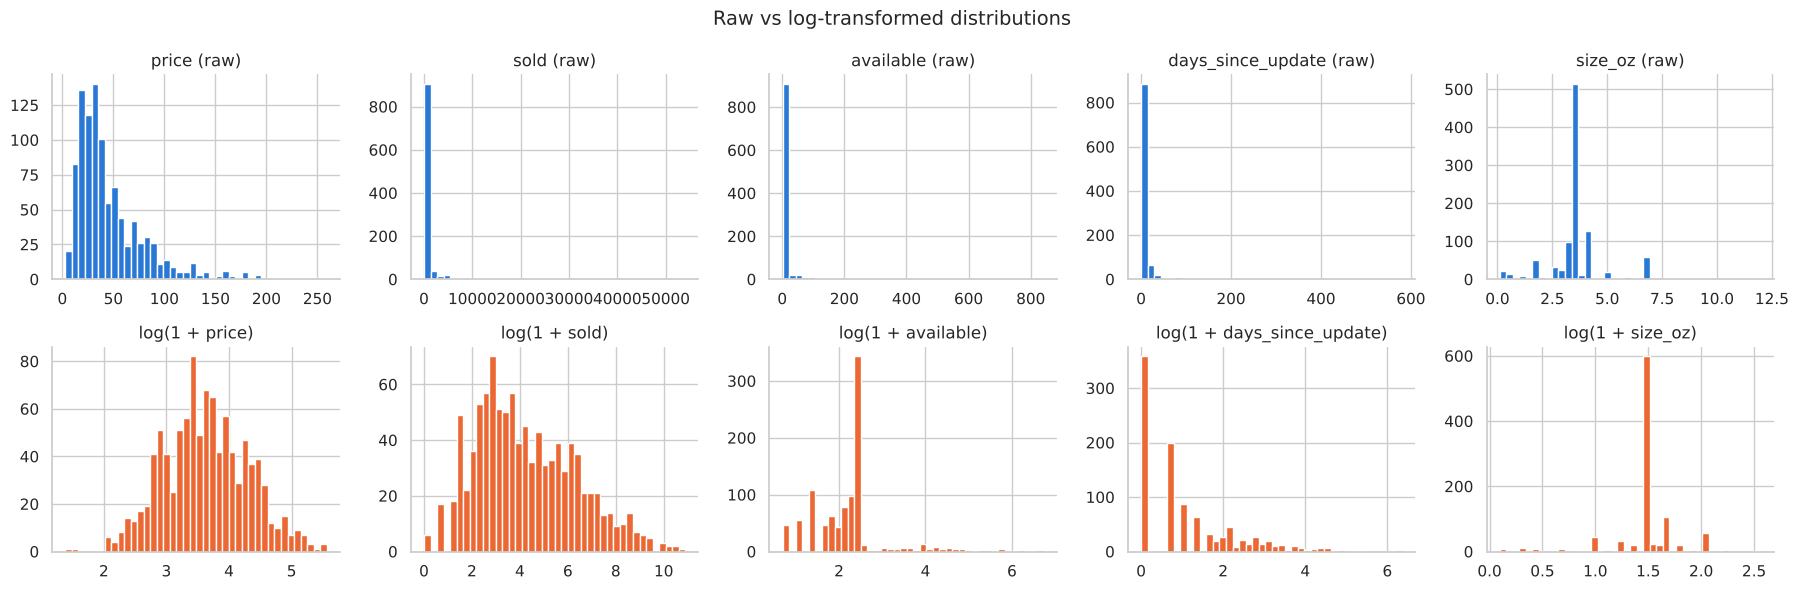

Skewness (raw):
price                 2.04
sold                  9.82
available             8.65
days_since_update    13.32
size_oz               0.82
dtype: float64


In [13]:
num = ['price', 'sold', 'available', 'days_since_update', 'size_oz']
fig, axes = plt.subplots(2, len(num), figsize=(18, 6))
for i, col in enumerate(num):
    axes[0, i].hist(df[col], bins=40, color=CLUSTER_COLOURS[0])
    axes[0, i].set_title(f'{col} (raw)')
    axes[1, i].hist(np.log1p(df[col]), bins=40, color=CLUSTER_COLOURS[1])
    axes[1, i].set_title(f'log(1 + {col})')
fig.suptitle('Raw vs log-transformed distributions', fontsize=14)
plt.tight_layout(); plt.show()

print('Skewness (raw):'); print(df[num].skew().round(2))

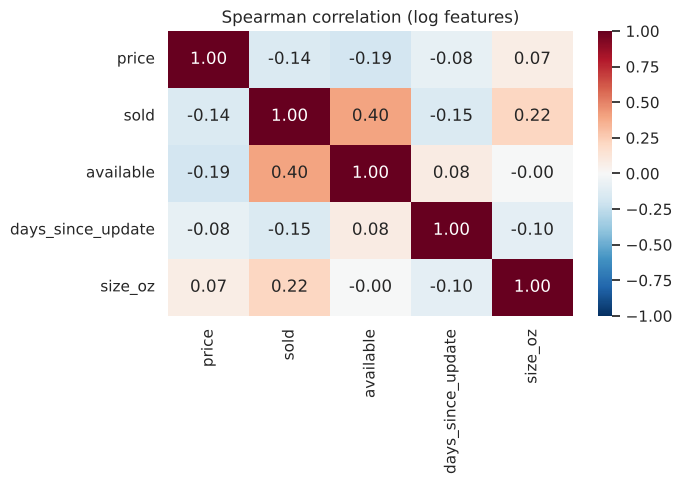

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
corr = np.log1p(df[num]).corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Spearman correlation (log features)')
plt.tight_layout(); plt.show()

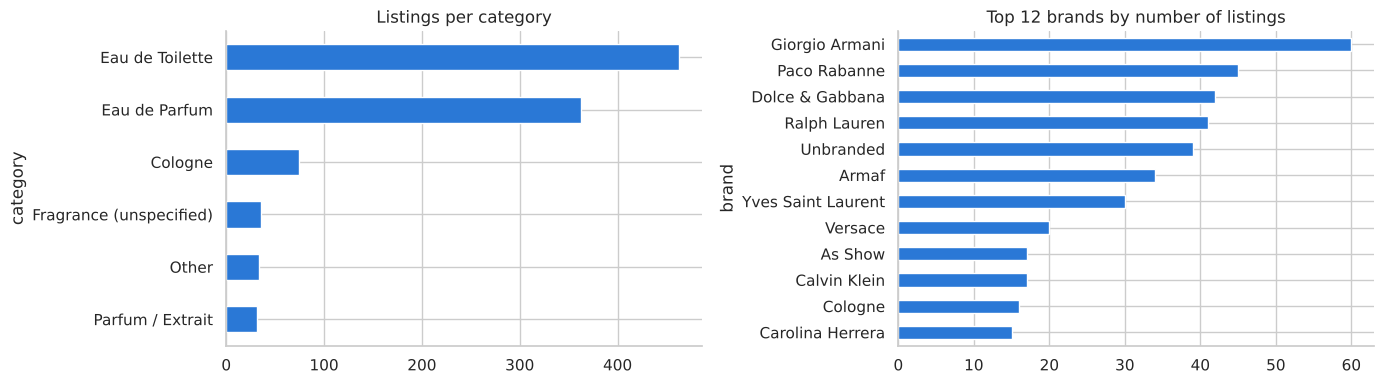

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['category'].value_counts().plot.barh(ax=axes[0], color=CLUSTER_COLOURS[0])
axes[0].set_title('Listings per category'); axes[0].invert_yaxis()
df['brand'].value_counts().head(12).plot.barh(ax=axes[1], color=CLUSTER_COLOURS[0])
axes[1].set_title('Top 12 brands by number of listings'); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

✍️ **Your analysis:** what do the distributions tell you? (Price and especially `sold` are heavily right-skewed: a few best-sellers with tens of thousands of sales.) What does that imply for K-Means, which uses squared Euclidean distance? Which features are strongly correlated and so might double-count the same information?

## 5. Feature selection and transformation

**Features selected for the main model** (characteristics + sales performance, as the brief asks):

| Feature | Why include it |
|---|---|
| `price` | Core product characteristic; drives positioning |
| `sold` | The sales-performance measure |
| `available` | Stock position; separates high-volume sellers from one-off listings |
| `days_since_update` | Listing activity/freshness; stale listings are a business issue |
| `size_oz` | Product characteristic; separates samples/travel sizes from full bottles |

**Excluded:** `details` (free text; would need NLP), `priceWithCurrency` and `text` (duplicates of price/sold/available), `Item_Name`/brand (228 levels; one-hot would swamp the numeric features with sparse dimensions), raw `itemLocation` (free text, 90 % US so little variance), `revenue = price × sold` (a combination of two features already included, so it would double-weight them).

**Categorical variables.** `category` (6 groups) and `us_seller` are one-hot/binary encoded and tested in section 11 as a sensitivity check rather than in the main model, because binary dimensions tend to dominate distance-based clustering and split the data along the dummy variables instead of along behaviour.

**Transformations.**
1. `log1p` on all numeric features to reduce skew so a few extreme best-sellers don't dominate distances.
2. Standardisation (z-score) so every feature has mean 0 and sd 1 and contributes equally. Min-max normalisation is compared below.

In [16]:
FEATURES = ['price', 'sold', 'available', 'days_since_update', 'size_oz']

X_log = np.log1p(df[FEATURES])
X_log.columns = [f'log_{c}' for c in FEATURES]

std_scaler = StandardScaler()
X = std_scaler.fit_transform(X_log)           # main matrix used for every model
X_minmax = MinMaxScaler().fit_transform(X_log)  # alternative, for comparison

pd.DataFrame(X, columns=X_log.columns).describe().round(2)

,log_price,log_sold,log_available,log_days_since_update,log_size_oz
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-3.34,-2.05,-1.67,-0.92,-4.35
25%,-0.67,-0.75,-0.66,-0.92,-0.01
50%,-0.04,-0.18,0.10,-0.34,0.07
75%,0.69,0.71,0.20,0.58,0.07
max,2.87,3.18,4.96,4.42,3.52


In [17]:
# Does the choice of scaler matter? Compare K-Means (k=4) silhouette under each
for name, M in [('No scaling (log only)', X_log.values), ('Min-max', X_minmax), ('Standard', X)]:
    labels = KMeans(4, n_init=20, random_state=RANDOM_STATE).fit_predict(M)
    print(f'{name:22s} silhouette = {silhouette_score(M, labels):.3f}   '
          f'cluster sizes = {np.bincount(labels).tolist()}')

No scaling (log only)  silhouette = 0.285   cluster sizes = [286, 353, 175, 186]
Min-max                silhouette = 0.207   cluster sizes = [262, 195, 261, 282]


Standard               silhouette = 0.227   cluster sizes = [290, 432, 211, 67]


✍️ **Your analysis:** note that silhouette scores from different scalings are measured in different spaces, so they are not strictly comparable. Justify standardisation on conceptual grounds (equal weighting, robust to the censored `available` maximum) rather than just picking the highest number.

## 6. Dimensionality reduction (PCA)

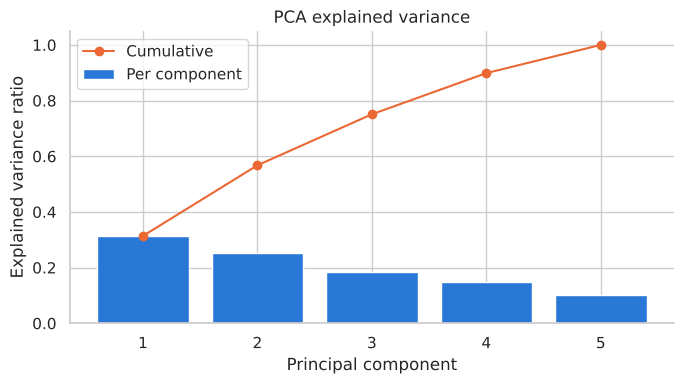

Cumulative variance, first 2 PCs: 56.8%, first 3: 75.1%


,PC1,PC2,PC3
log_price,-0.30,0.59,0.22
log_sold,0.67,0.11,0.02
log_available,0.63,-0.14,0.14
log_days_since_update,-0.15,-0.49,0.84
log_size_oz,0.19,0.62,0.48


In [18]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(evr) + 1), evr, color=CLUSTER_COLOURS[0], label='Per component')
ax.plot(range(1, len(evr) + 1), np.cumsum(evr), marker='o', color=CLUSTER_COLOURS[1], label='Cumulative')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA explained variance'); ax.legend()
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=X_log.columns, columns=['PC1', 'PC2', 'PC3'])
print('Cumulative variance, first 2 PCs: {:.1%}, first 3: {:.1%}'.format(evr[:2].sum(), evr[:3].sum()))
loadings.round(2)

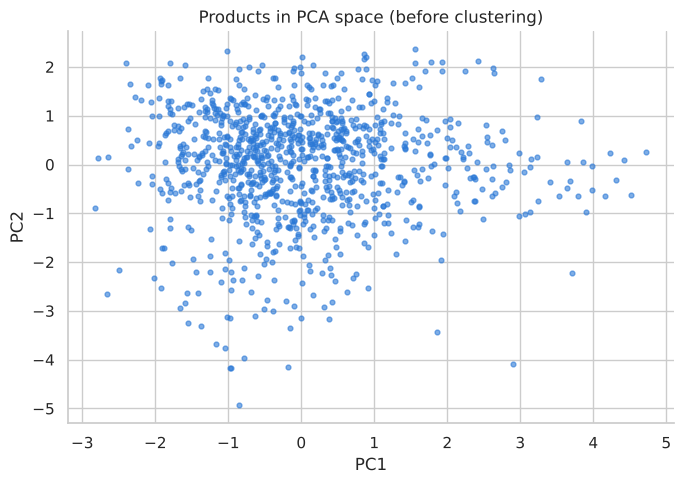

In [19]:
X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

def plot_clusters(labels, title, ax=None):
    # Scatter of the 2-D PCA projection, one fixed colour per cluster, noise in grey
    ax = ax or plt.subplots(figsize=(7, 5))[1]
    for k in sorted(set(labels)):
        m = labels == k
        colour = NOISE_COLOUR if k == -1 else CLUSTER_COLOURS[k % len(CLUSTER_COLOURS)]
        name = 'Noise' if k == -1 else f'Cluster {k}'
        ax.scatter(X_pca2[m, 0], X_pca2[m, 1], s=14, alpha=0.7, color=colour,
                   label=f'{name} (n={m.sum()})', edgecolor='white', linewidth=0.3)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)
    return ax

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_pca2[:, 0], X_pca2[:, 1], s=12, alpha=0.6, color=CLUSTER_COLOURS[0])
ax.set_title('Products in PCA space (before clustering)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

✍️ **Your analysis:** interpret the loadings (which features drive PC1 and PC2?). Explain that PCA is used here for **visualisation**; clustering runs on all 5 scaled features, because with only 5 features there is little to gain from reducing dimensions and we'd lose information. (You could test clustering on the first 3 PCs as an extension.)

## 7. K-Means

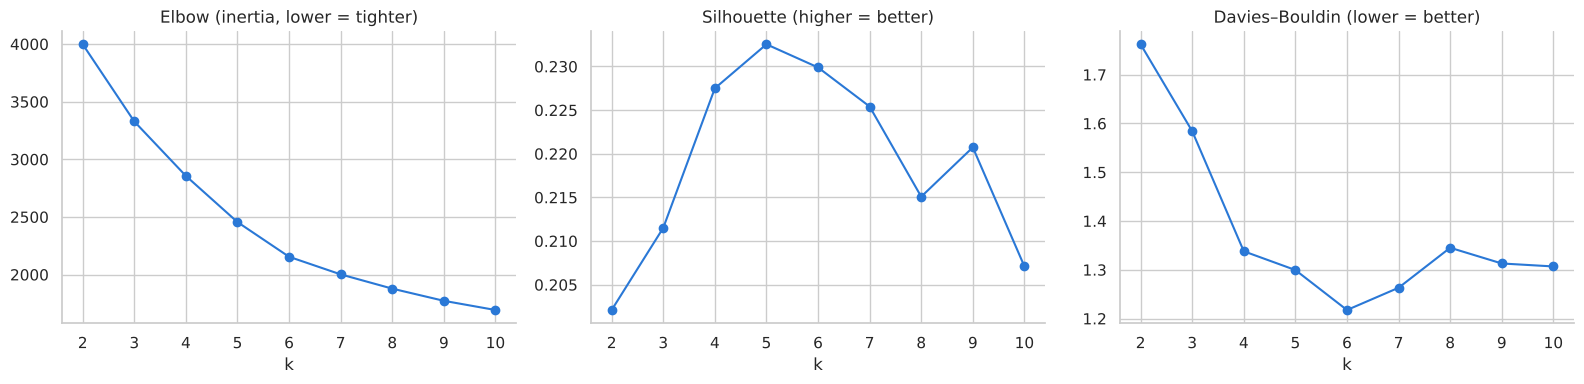

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,3998.060,0.202,1.762,250.109
3,3328.429,0.212,1.584,250.352
4,2856.028,0.227,1.338,249.227
5,2455.279,0.233,1.299,257.812
6,2154.378,0.230,1.218,262.586
7,2001.728,0.225,1.263,247.893
8,1877.945,0.215,1.345,235.598
9,1772.325,0.221,1.313,225.595
10,1692.589,0.207,1.307,214.946


In [20]:
k_range = range(2, 11)
rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X, km.labels_),
                 'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
k_scores = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_scores.index, k_scores['inertia'], marker='o', color=CLUSTER_COLOURS[0]); axes[0].set_title('Elbow (inertia, lower = tighter)')
axes[1].plot(k_scores.index, k_scores['silhouette'], marker='o', color=CLUSTER_COLOURS[0]); axes[1].set_title('Silhouette (higher = better)')
axes[2].plot(k_scores.index, k_scores['davies_bouldin'], marker='o', color=CLUSTER_COLOURS[0]); axes[2].set_title('Davies–Bouldin (lower = better)')
for a in axes: a.set_xlabel('k')
plt.tight_layout(); plt.show()
k_scores.round(3)

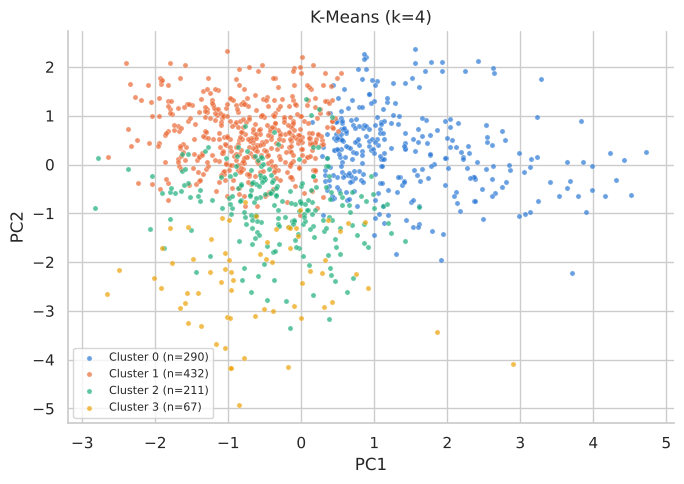

In [21]:
K = 4  # chosen from the elbow + silhouette + DB plots AND interpretability; justify in your write-up
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
df['kmeans'] = kmeans.labels_
plot_clusters(df['kmeans'].values, f'K-Means (k={K})'); plt.tight_layout(); plt.show()

✍️ **Your analysis:** k=4 and k=5 score almost identically on silhouette, and Davies–Bouldin is slightly better at 5. Argue for your choice using both the metrics and how usable the segments are for the business (fewer, clearly different segments are easier to act on).

## 8. Hierarchical (agglomerative) clustering

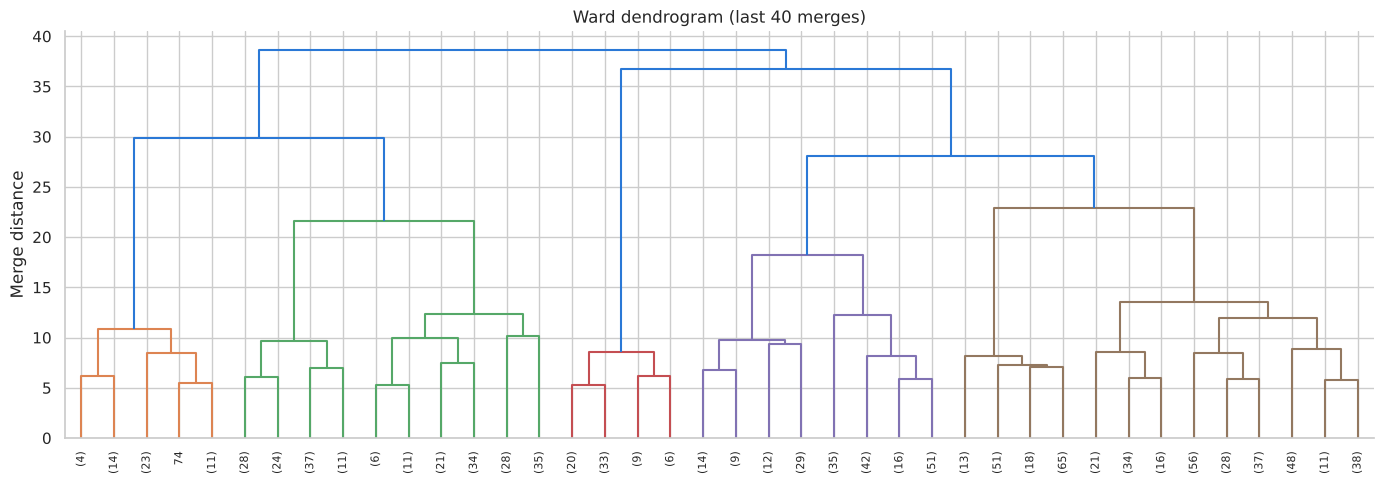

In [22]:
# Dendrogram using Ward linkage (merges clusters that least increase within-cluster variance)
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=40, leaf_rotation=90, ax=ax, color_threshold=None,
           above_threshold_color=CLUSTER_COLOURS[0])
ax.set_title('Ward dendrogram (last 40 merges)'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.show()

In [23]:
# Compare linkage criteria across k
rows = []
for method in ['ward', 'complete', 'average']:
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        rows.append({'linkage': method, 'k': k,
                     'silhouette': silhouette_score(X, lab),
                     'davies_bouldin': davies_bouldin_score(X, lab),
                     'smallest_cluster': np.bincount(lab).min()})
hier_scores = pd.DataFrame(rows)
hier_scores.pivot(index='k', columns='linkage', values=['silhouette', 'smallest_cluster']).round(3)

silhouette                 smallest_cluster                
linkage    average complete   ward          average complete   ward
k                                                                  
2            0.502    0.325  0.200              2.0     81.0  288.0
3            0.352    0.284  0.225              2.0     59.0   68.0
4            0.332    0.272  0.223              1.0      9.0   53.0
5            0.261    0.168  0.192              1.0      9.0   53.0
6            0.265    0.144  0.163              1.0      9.0   53.0
7            0.253    0.141  0.178              1.0      9.0   53.0
8            0.218    0.133  0.187              1.0      9.0   53.0

Average and complete linkage often get high silhouettes by putting nearly everything in one cluster and isolating a few outliers (look at `smallest_cluster`). That is not useful segmentation, so Ward is preferred.

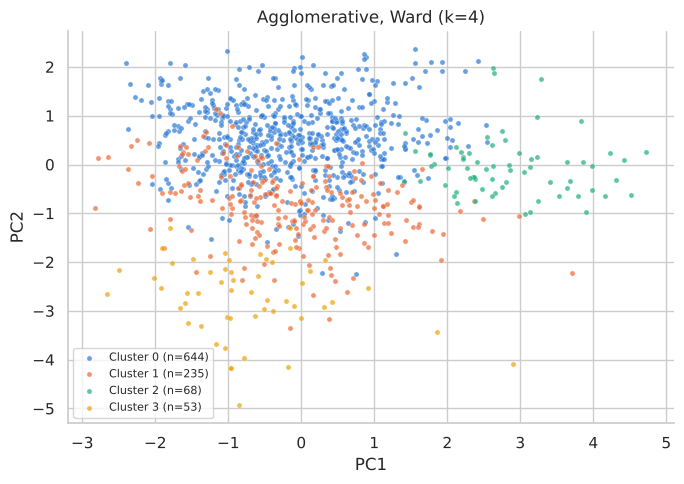

In [24]:
hier = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X)
df['hierarchical'] = hier.labels_
plot_clusters(df['hierarchical'].values, f'Agglomerative, Ward (k={K})'); plt.tight_layout(); plt.show()

## 9. DBSCAN

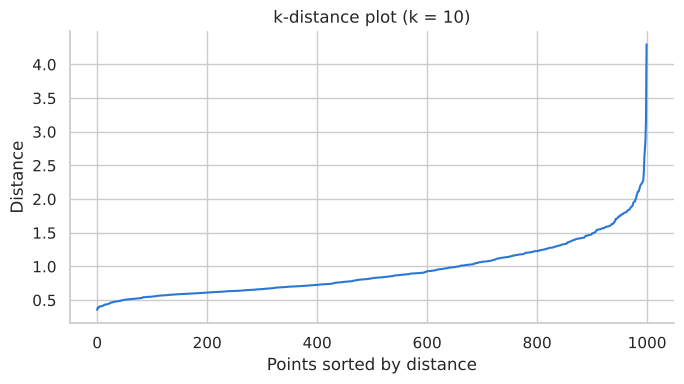

In [25]:
# Choose eps with the k-distance plot: distance to each point's MIN_SAMPLES-th neighbour, sorted.
# The 'knee' of the curve is a sensible eps. Rule of thumb: min_samples ≈ 2 × number of features.
MIN_SAMPLES = 2 * X.shape[1]
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(kdist, color=CLUSTER_COLOURS[0])
ax.set_title(f'k-distance plot (k = {MIN_SAMPLES})'); ax.set_xlabel('Points sorted by distance'); ax.set_ylabel('Distance')
plt.tight_layout(); plt.show()

In [26]:
rows = []
for eps in np.arange(0.5, 1.45, 0.1):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    core = lab != -1
    n_clusters = len(set(lab[core]))
    sil = silhouette_score(X[core], lab[core]) if n_clusters > 1 else np.nan
    rows.append({'eps': round(eps, 2), 'clusters': n_clusters,
                 'noise_pct': round(100 * (~core).mean(), 1), 'silhouette_excl_noise': sil})
dbscan_scores = pd.DataFrame(rows)
dbscan_scores.round(3)

,eps,clusters,noise_pct,silhouette_excl_noise
0,0.5,7,84.6,0.396
1,0.6,2,62.7,0.342
2,0.7,2,46.1,0.172
3,0.8,3,35.4,0.182
4,0.9,3,25.9,0.185
5,1.0,1,18.8,NaN
6,1.1,1,14.4,NaN
7,1.2,2,8.8,0.416
8,1.3,2,5.2,0.405
9,1.4,2,3.4,0.405


eps=1.2: {0: 898, -1: 88, 1: 14}


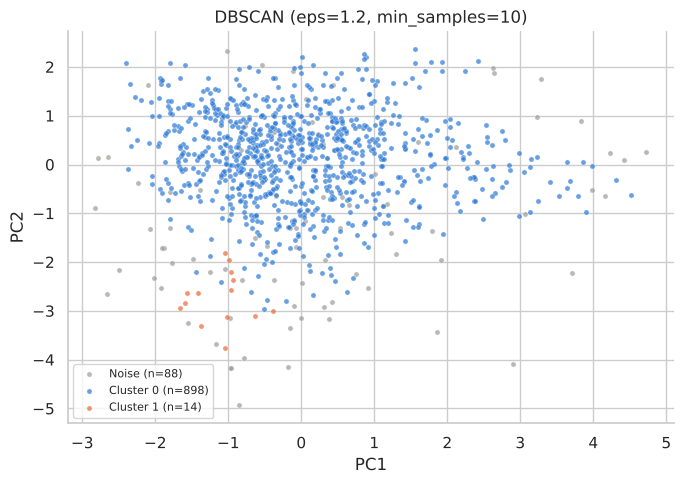

In [27]:
# Pick the eps that gives >1 cluster with the best silhouette and noise under ~20 %
candidates = dbscan_scores[(dbscan_scores.clusters > 1) & (dbscan_scores.noise_pct < 20)]
EPS = candidates.sort_values('silhouette_excl_noise', ascending=False)['eps'].iloc[0]
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
df['dbscan'] = dbscan.labels_
print(f'eps={EPS}:', df['dbscan'].value_counts().to_dict())
plot_clusters(df['dbscan'].values, f'DBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'); plt.tight_layout(); plt.show()

✍️ **Your analysis:** DBSCAN finds dense regions and labels everything else as noise. Here the data forms one large dense mass, so DBSCAN tends to return one big cluster plus a small one and a noise set. Discuss: is that a failure, or useful? (The noise points are unusual listings, e.g. extreme best-sellers or very large stock. That is useful for anomaly review but not for segmentation.)

## 10. Model comparison and stability

In [28]:
def evaluate(name, labels, M=X):
    core = labels != -1
    n = len(set(labels[core]))
    out = {'model': name, 'clusters': n, 'noise_pct': round(100 * (~core).mean(), 1)}
    if n > 1:
        out.update({'silhouette': silhouette_score(M[core], labels[core]),
                    'davies_bouldin': davies_bouldin_score(M[core], labels[core]),
                    'calinski_harabasz': calinski_harabasz_score(M[core], labels[core])})
    out['smallest_cluster'] = np.bincount(labels[core]).min()
    return out

comparison = pd.DataFrame([
    evaluate(f'K-Means (k={K})', df['kmeans'].values),
    evaluate(f'Agglomerative Ward (k={K})', df['hierarchical'].values),
    evaluate(f'DBSCAN (eps={EPS})', df['dbscan'].values),
]).set_index('model')
comparison.round(3)

,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster
model,,,,,,
K-Means (k=4),4,0.0,0.227,1.338,249.227,67
Agglomerative Ward (k=4),4,0.0,0.223,1.408,197.542,53
DBSCAN (eps=1.2),2,8.8,0.416,0.671,57.875,14


In [29]:
# Stability: refit each model on 20 bootstrap samples (80 % of rows) and compare the labels
# it gives with the full-data labels on the same rows (Adjusted Rand Index; 1 = identical).
rng = np.random.default_rng(RANDOM_STATE)
stab = {'K-Means': [], 'Agglomerative': [], 'DBSCAN': []}
for _ in range(20):
    idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    Xb = X[idx]
    stab['K-Means'].append(adjusted_rand_score(df['kmeans'].values[idx],
        KMeans(K, n_init=10, random_state=int(rng.integers(1e6))).fit_predict(Xb)))
    stab['Agglomerative'].append(adjusted_rand_score(df['hierarchical'].values[idx],
        AgglomerativeClustering(K, linkage='ward').fit_predict(Xb)))
    stab['DBSCAN'].append(adjusted_rand_score(df['dbscan'].values[idx],
        DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Xb)))
stability = pd.DataFrame(stab).agg(['mean', 'std']).T.round(3)
comparison['stability_ARI'] = stability['mean'].values
comparison.round(3)

,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,stability_ARI
model,,,,,,,
K-Means (k=4),4,0.0,0.227,1.338,249.227,67,0.875
Agglomerative Ward (k=4),4,0.0,0.223,1.408,197.542,53,0.532
DBSCAN (eps=1.2),2,8.8,0.416,0.671,57.875,14,0.879


ARI K-Means vs Agglomerative: 0.385
Crosstab:


Ward,0,1,2,3
K-Means,,,,
0,187,35,68,0
1,413,19,0,0
2,27,180,0,4
3,17,1,0,49


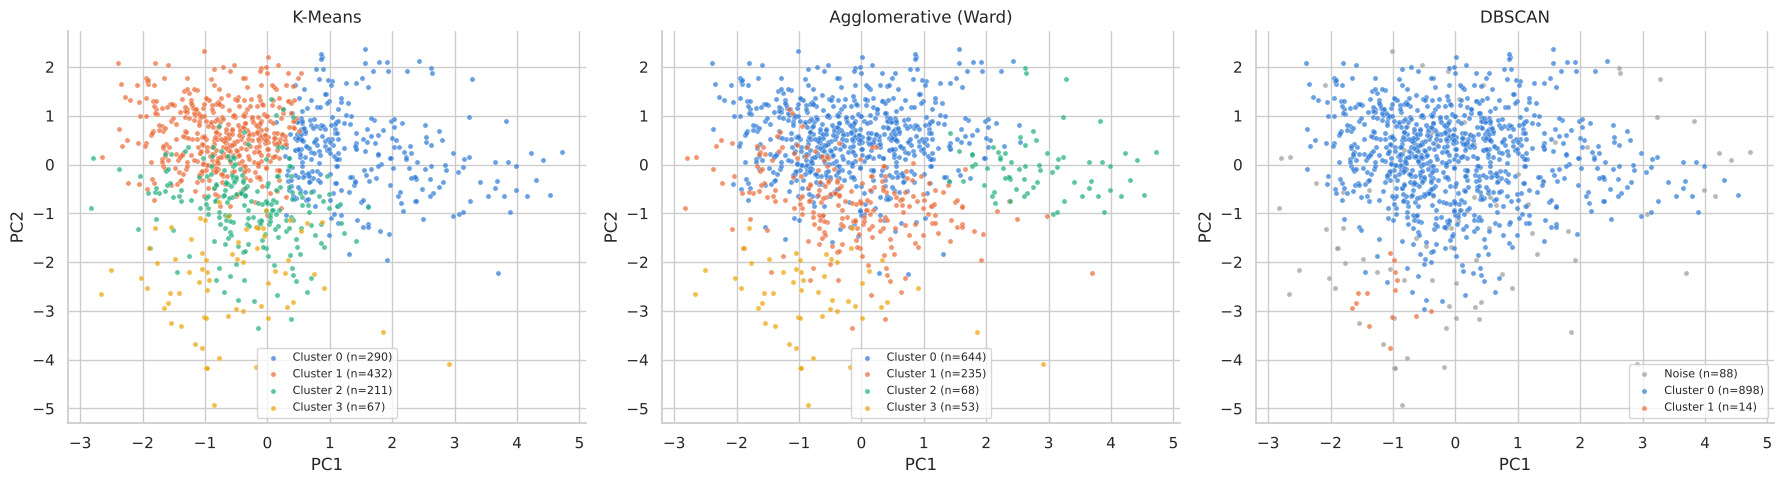

In [30]:
# Agreement between methods (how similar are the partitions?)
print('ARI K-Means vs Agglomerative:', round(adjusted_rand_score(df['kmeans'], df['hierarchical']), 3))
print('Crosstab:'); display(pd.crosstab(df['kmeans'], df['hierarchical'], rownames=['K-Means'], colnames=['Ward']))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_clusters(df['kmeans'].values, 'K-Means', axes[0])
plot_clusters(df['hierarchical'].values, 'Agglomerative (Ward)', axes[1])
plot_clusters(df['dbscan'].values, 'DBSCAN', axes[2])
plt.tight_layout(); plt.show()

✍️ **Your analysis (key marks here):** compare the three models on (a) internal validity (silhouette, DB, CH), (b) stability, (c) cluster balance and (d) business usefulness. Note the modest silhouette (about 0.22) for all models: real product data rarely has crisp, well-separated groups, so the clusters are better described as *segments along a continuum*. Then justify your final model choice on technical **and** business grounds (e.g. K-Means: stable, assigns every product, centroids are easy to explain to managers, scales to the full catalogue and can label new products with `predict`).

## 11. Sensitivity check: adding categorical features

In [31]:
# One-hot encode the cleaned category and add the US-seller flag to the scaled numeric features
try:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')  # scikit-learn 1.2+
except TypeError:
    ohe = OneHotEncoder(sparse=False, handle_unknown='ignore')         # older scikit-learn
cat = ohe.fit_transform(df[['category']])
X_cat = np.hstack([X, cat, df[['us_seller']].values])
print('Feature matrix with categoricals:', X_cat.shape)

km_cat = KMeans(K, n_init=20, random_state=RANDOM_STATE).fit_predict(X_cat)
print('Silhouette with categoricals:', round(silhouette_score(X_cat, km_cat), 3))
print('ARI vs numeric-only K-Means:', round(adjusted_rand_score(df['kmeans'], km_cat), 3))
pd.crosstab(km_cat, df['category'], rownames=['cluster (with categoricals)'])

Feature matrix with categoricals: (1000, 12)
Silhouette with categoricals: 0.191
ARI vs numeric-only K-Means: 0.851


category,Cologne,Eau de Parfum,Eau de Toilette,Fragrance (unspecified),Other,Parfum / Extrait
cluster (with categoricals),,,,,,
0,28,184,147,30,16,19
1,18,54,197,2,4,3
2,11,35,17,2,4,1
3,17,90,102,2,9,8


✍️ **Your analysis:** did adding the dummies change the clusters a lot? Did clusters start aligning with category rather than with price/sales behaviour? Use this to justify keeping categoricals out of the main model and using them for *profiling* instead (section 12). Mention alternatives such as K-Prototypes or Gower distance for mixed data.

## 12. Cluster profiles and business interpretation (final model: K-Means)

In [32]:
FINAL = 'kmeans'
profile = df.groupby(FINAL).agg(
    products=('price', 'size'),
    median_price=('price', 'median'),
    median_sold=('sold', 'median'),
    total_sold=('sold', 'sum'),
    median_available=('available', 'median'),
    median_days_since_update=('days_since_update', 'median'),
    median_size_oz=('size_oz', 'median'),
    pct_us_seller=('us_seller', 'mean'),
)
profile['share_of_units_sold_%'] = 100 * profile['total_sold'] / profile['total_sold'].sum()
profile['est_revenue'] = df.assign(rev=df.price * df.sold).groupby(FINAL)['rev'].sum()
profile.round(2)

,products,median_price,median_sold,total_sold,median_available,median_days_since_update,median_size_oz,pct_us_seller,share_of_units_sold_%,est_revenue
kmeans,,,,,,,,,,
0,290,29.76,635.0,689606.0,10.0,0.0,3.4,0.99,90.54,23024333.85
1,432,49.99,20.0,23128.0,5.0,1.0,3.4,0.86,3.04,1769203.18
2,211,29.99,31.0,21965.0,10.0,15.0,3.4,0.90,2.88,716196.41
3,67,20.00,20.0,26970.0,10.0,2.0,0.5,0.97,3.54,298244.53


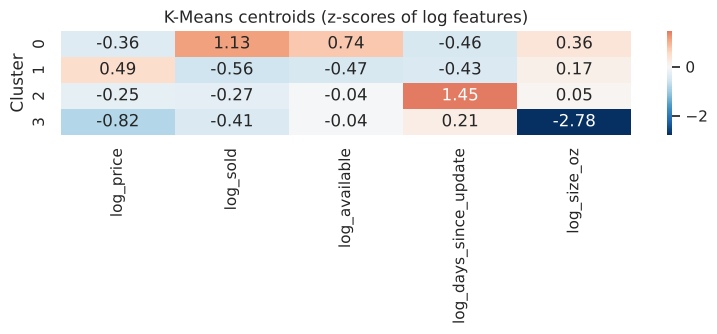

In [33]:
# Standardised centroids: how far each cluster sits above/below the average on each feature
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=X_log.columns)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(centroids, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('K-Means centroids (z-scores of log features)'); ax.set_ylabel('Cluster')
plt.tight_layout(); plt.show()

/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in r

/tmp/ipykernel_259/4020995806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)


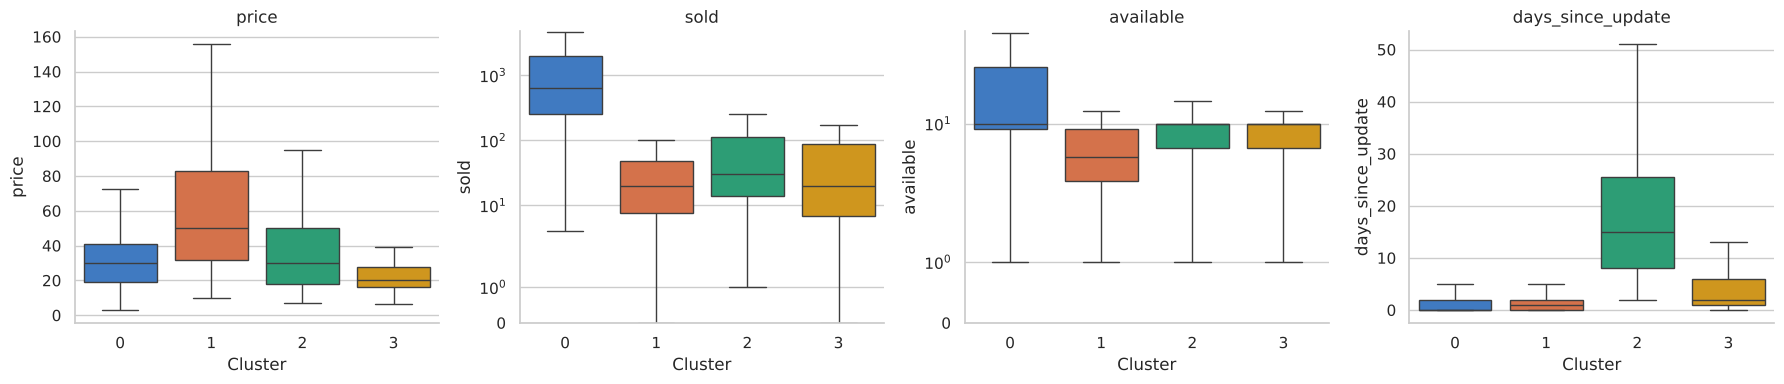

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
palette = {k: CLUSTER_COLOURS[k] for k in range(K)}
for ax, col in zip(axes, ['price', 'sold', 'available', 'days_since_update']):
    sns.boxplot(data=df, x=FINAL, y=col, order=list(range(K)), palette=[palette[k] for k in range(K)], ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel('Cluster')
    if col in ('sold', 'available'):
        ax.set_yscale('symlog')
        ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

In [35]:
# Category mix (%) and top brands per cluster: categorical variables used for profiling
display((pd.crosstab(df[FINAL], df['category'], normalize='index') * 100).round(1))
for k in range(K):
    print(f'Cluster {k} top brands:', df.loc[df[FINAL] == k, 'brand'].value_counts().head(6).to_dict())

category,Cologne,Eau de Parfum,Eau de Toilette,Fragrance (unspecified),Other,Parfum / Extrait
kmeans,,,,,,
0,6.9,24.1,63.8,1.4,2.1,1.7
1,6.9,39.8,38.7,6.7,3.5,4.4
2,6.2,41.7,44.5,0.5,4.3,2.8
3,16.4,49.3,25.4,3.0,4.5,1.5


Cluster 0 top brands: {'Armaf': 16, 'Ralph Lauren': 14, 'Dolce & Gabbana': 13, 'Giorgio Armani': 13, 'Calvin Klein': 10, 'Azzaro': 9}
Cluster 1 top brands: {'Giorgio Armani': 35, 'Paco Rabanne': 28, 'Dolce & Gabbana': 21, 'Unbranded': 17, 'Yves Saint Laurent': 17, 'As Show': 15}
Cluster 2 top brands: {'Ralph Lauren': 10, 'Unbranded': 8, 'Giorgio Armani': 8, 'Paco Rabanne': 8, 'Dolce & Gabbana': 6, 'Armaf': 6}
Cluster 3 top brands: {'Unbranded': 7, 'Dossier': 5, 'Giorgio Armani': 4, 'Yves Saint Laurent': 4, 'Hermes': 3, 'Ralph Lauren': 3}


✍️ **Your analysis:** give each cluster a business name based on its profile (for example "High-volume best-sellers", "Premium slow movers", "Stale listings", "Everyday mid-range"), and recommend an action for each (restock, reprice, promote, review/delist). Check the names against the numbers above before you use them. These names and recommendations go straight into your Task 2 executive report.

## 13. Export

In [36]:
out_cols = ['brand', 'details', 'category', 'price', 'sold', 'available', 'days_since_update',
            'size_oz', 'country', 'kmeans', 'hierarchical', 'dbscan']
df[out_cols].to_csv('sales_clustered.csv', index=False)
print('Saved sales_clustered.csv with', len(df), 'rows')

Saved sales_clustered.csv with 1000 rows


## Limitations and possible improvements (prompt list for your write-up)
- `available` is censored at 10 ("More than 10 available"), and `sold` is lifetime sales with no time window.
- The data is one snapshot (mostly May 2024), so there's no trend information.
- Listing titles (`details`) were only used for bottle size; TF-IDF or embeddings could add product-type information.
- Brand was excluded from clustering; target encoding or a brand-tier feature could add it.
- Try Gaussian Mixture Models (soft clusters), K-Prototypes for mixed data, or HDBSCAN (varying density).
- Validate the segments with the business (do merchandisers agree?) and track them over time.